# Part 1. Comparing Yandex Books User Activity in Moscow and Saint Petersburg

The study uses preprocessed data on Yandex Books users from Moscow and Saint Petersburg. Total reading and listening time in hours has been calculated for each user.

We will test the hypothesis that users from Saint Petersburg spend more time in the app on average than users from Moscow.

Null hypothesis:

$$
H_0: \mu_{\text{Saint Petersburg}} \leq \mu_{\text{Moscow}}
$$

The mean activity time of users from Saint Petersburg does not exceed that of users from Moscow.

Alternative hypothesis:

$$
H_1: \mu_{\text{Saint Petersburg}} > \mu_{\text{Moscow}}
$$

The mean activity time of users from Saint Petersburg is higher.

Before statistical testing, we will examine sample sizes, repeated users, descriptive statistics, and distributions. We will prepare an analytical report based on the test results.

- Author: Nila Sisakyan
- Date: August 3, 2026

## Project Goals and Objectives

The project aims to test the hypothesis that users from Saint Petersburg spend more time reading and listening to books in the app than users from Moscow.

To achieve this goal, the following tasks need to be completed:

* load and explore the prepared data on users from Moscow and Saint Petersburg;
* check the data for duplicates and assess the sample sizes;
* perform descriptive analysis and compare the main statistical characteristics of the two groups;
* select an appropriate statistical test and perform a one-sided two-sample t-test;
* analyze the resulting p-value and determine whether there are statistically significant differences in mean activity time between users from the two cities;
* prepare an analytical report interpreting the results and suggesting possible reasons for the observed differences.

## Data Description

The source data consists of the `bookmate.audition`, `bookmate.content`, `bookmate.author`, and `bookmate.geo` tables.

This notebook analyzes the prepared `yandex_knigi_data.csv` export, which contains the city, user identifier, and total user activity time. The source tables are described to provide context on the data structure.

### `bookmate.audition` Table

Contains information on user activity.

| Field | Description |
| ----- | ----------- |
| `audition_id` | unique identifier of a reading or listening session |
| `puid` | user identifier |
| `usage_platform_ru` | name of the platform used to listen to content |
| `msk_business_dt_str` | event date as a string (Moscow time) |
| `app_version` | app version used for reading or listening |
| `adult_content_flg` | adult content indicator (`True` or `False`) |
| `hours` | reading or listening duration in hours |
| `hours_sessions_long` | duration of long reading or listening sessions in hours |
| `kids_content_flg` | children's content indicator (`True` or `False`) |
| `main_content_id` | main content identifier |
| `usage_geo_id` | geographic location identifier |

### `bookmate.content` Table

Contains information on content.

| Field | Description |
| ----- | ----------- |
| `main_content_id` | main content identifier |
| `main_author_id` | main content author identifier |
| `main_content_type` | content type |
| `main_content_name` | content title |
| `main_content_duration_hours` | content duration in hours |
| `published_topic_title_list` | list of content genres |

### `bookmate.author` Table

Contains information on content authors.

| Field | Description |
| ----- | ----------- |
| `main_author_id` | main content author identifier |
| `main_author_name` | main content author name |

### `bookmate.geo` Table

Contains information on users' geographic locations.

| Field | Description |
| ----- | ----------- |
| `usage_geo_id` | geographic location identifier |
| `usage_geo_id_name` | city or region of the geographic location |
| `usage_country_name` | country of the geographic location |


### `yandex_knigi_data` After Preprocessing

| Field | Description |
| ----- | ----------- |
| `city` | city |
| `puid` | user identifier |
| `hours` | total reading or listening duration in hours |

## Project Contents

**Project Plan**

1. Loading and exploring the data.
2. Hypothesis testing in Python.
3. Analytical report

## 1. Loading and Exploring the Data

We will load `yandex_knigi_data.csv`, which contains data on users from Moscow and Saint Petersburg and their total reading and listening time.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [2]:
df = pd.read_csv('https://code.s3.yandex.net/datasets/yandex_knigi_data.csv')

Display the first rows of the DataFrame:

In [3]:
df.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


Check for duplicate user identifiers:

In [4]:
df['puid'].duplicated().sum()

np.int64(244)

Examine all records for users with repeated identifiers:

In [5]:
duplicates = df[df['puid'].duplicated(keep=False)]

duplicates.sort_values('puid')

,Unnamed: 0,city,puid,hours
6247,6247,Санкт-Петербург,2637041,3.883926
35,35,Москва,2637041,10.317371
134,134,Москва,9979490,32.415573
6274,6274,Санкт-Петербург,9979490,1.302997
145,145,Москва,10597984,42.931506
...,...,...,...,...
8773,8773,Санкт-Петербург,1130000020425037,2.386944
6202,6202,Москва,1130000023864516,142.830085
8775,8775,Санкт-Петербург,1130000023864516,14.384722
8779,8779,Санкт-Петербург,1130000028554332,4.107774


Identify users with records for more than one city:

In [6]:
user_cities = (
    df.groupby('puid')['city']
    .nunique()
)

user_cities[user_cities > 1]

puid
2637041             2
9979490             2
10597984            2
10815097            2
13626259            2
                   ..
1130000018516717    2
1130000018954257    2
1130000020425037    2
1130000023864516    2
1130000028554332    2
Name: city, Length: 244, dtype: int64

Calculate the share of users with records in both cities:

In [7]:
df['puid'].duplicated().sum() / df['puid'].nunique() * 100

np.float64(2.857142857142857)

The data contains 244 users (approximately 2.86%) with records in both cities. These users may violate the independence of the samples, so they were excluded from the analysis before statistical testing.

Exclude users with records in multiple cities:

In [8]:
multi_city_users = user_cities[user_cities > 1].index
df_clean = df[~df['puid'].isin(multi_city_users)]

Create separate activity time samples for users from Saint Petersburg and Moscow:

In [10]:
spb = df_clean[df_clean['city'] == 'Санкт-Петербург']['hours']

moscow = df_clean[df_clean['city'] == 'Москва']['hours']

Descriptive statistics for the activity time of users from Saint Petersburg:

In [11]:
spb.describe()

count    2306.000000
mean       11.264433
std        39.831755
min         0.000025
25%         0.060173
50%         0.875355
75%         6.138424
max       978.764775
Name: hours, dtype: float64

Descriptive statistics for the activity time of users from Moscow:

In [12]:
moscow.describe()

count    5990.000000
mean       10.848192
std        36.925622
min         0.000022
25%         0.057042
50%         0.888232
75%         5.933439
max       857.209373
Name: hours, dtype: float64

Examine the data distributions

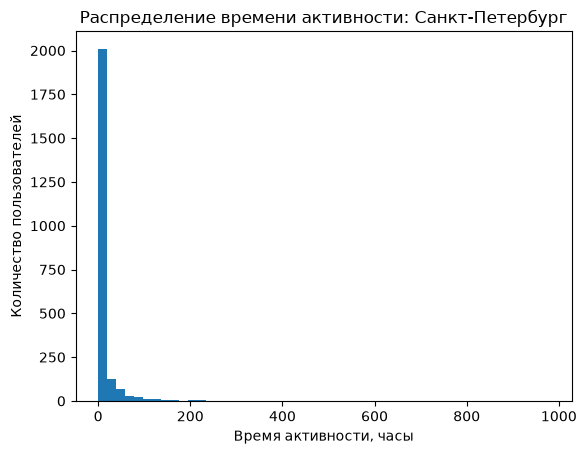

In [14]:
plt.hist(spb, bins=50)
plt.title('Activity Time Distribution: Saint Petersburg')
plt.xlabel('Activity time, hours')
plt.ylabel('Number of users')
plt.show()

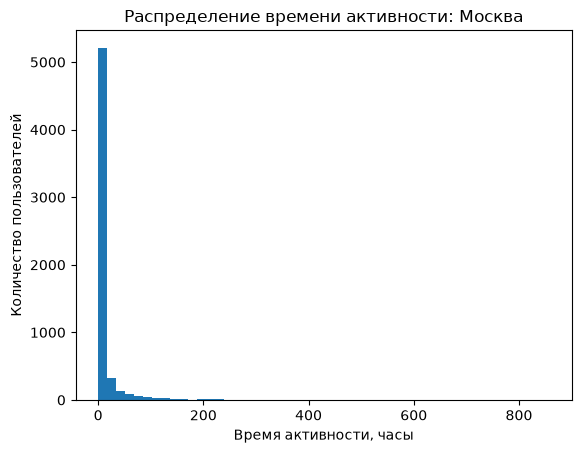

In [15]:
plt.hist(moscow, bins=50)
plt.title('Activity Time Distribution: Moscow')
plt.xlabel('Activity time, hours')
plt.ylabel('Number of users')
plt.show()

The sample sizes for users from Saint Petersburg and Moscow differ: 2,306 and 5,990 users, respectively. However, the difference in group sizes is not critical for applying a two-sample t-test. The activity time distributions show strong right skewness and outliers: most users have a small number of activity hours, while a small group of users have substantially higher values. Therefore, Welch's t-test, which accommodates differences in sample sizes and variances, was selected to test the hypothesis.

## 2. Hypothesis Testing in Python

We will test whether the mean activity time of users from Saint Petersburg exceeds that of users from Moscow.

- H₀: mean activity time in Saint Petersburg does not exceed mean activity time in Moscow.
- H₁: mean activity time in Saint Petersburg is higher than mean activity time in Moscow.

We will use a one-sided Welch's t-test with a significance level of α = 0.05.

In [17]:
alpha = 0.05

stat_welch_ttest, p_value_welch_ttest = ttest_ind(
    spb,
    moscow,
    alternative='greater',
    equal_var=False,
)

if p_value_welch_ttest > alpha:
    print(f'Welch test p-value = {round(p_value_welch_ttest, 2)}')
    print('The null hypothesis is supported! Mean user activity in hours does not differ between the two groups')
else:
    print(f'Welch test p-value ={round(p_value_welch_ttest, 2)}')
    print('The null hypothesis is not supported!  Mean user activity in Saint Petersburg is higher, and the difference is statistically significant')

Welch test p-value = 0.33
The null hypothesis is supported! Mean user activity in hours does not differ between the two groups


## 3. Analytical Report

**Analysis Objective**

The objective of the study was to test the hypothesis that users from Saint Petersburg spend more time reading and listening to content in the Yandex Books app than users from Moscow.

The following statistical hypotheses were formulated:

* **H₀:** the mean activity time of users from Saint Petersburg is not greater than that of users from Moscow.
* **H₁:** the mean activity time of users from Saint Petersburg is greater than that of users from Moscow.

**Data Preparation**

Data quality was checked before statistical testing. Users appearing in the data for both cities were identified. These users could violate the independence of the samples, so they were excluded from further analysis.

After cleaning, the sample sizes were:

* Saint Petersburg — 2,306 users;
* Moscow — 5,990 users.

The distribution of user activity time was also analyzed. Strong right skewness was observed: most users have a small number of activity hours, while a small group have substantially higher values. Therefore, Welch's t-test was chosen to compare the groups, accounting for possible differences in variances between the samples.

**Statistical Test Results**

A one-sided Welch's t-test was applied with a significance level of:

α = 0.05.

The resulting p-value:

**p-value = 0.33**

Since the p-value is greater than the significance level of 0.05, no statistically significant differences between the groups were detected.

**Conclusions**

The analysis did not confirm the hypothesis that users from Saint Petersburg spend more time in the app than users from Moscow.

The observed difference in mean user activity is not statistically significant, so we cannot conclude that the city of residence affects the duration of app usage.

Possible reasons for the absence of differences:

* app users may exhibit similar behavior regardless of their city;
* differences in activity may be driven by other factors, such as user age, content preferences, or app usage frequency.

Thus, the current data provides no grounds to claim that users from Saint Petersburg are more active than users from Moscow. A deeper analysis could examine other factors, such as platform, content type, or user segment.

# Part 2. A/B Test of a New Online Store Interface

The online store BitMotion Kit sells gamified products for a healthy lifestyle. According to user reviews, the current store interface is too complicated.

The team developed a new version of the website and conducted an A/B test, expecting an increase in the share of users making a purchase.

The objective of the study is to check that the experiment was conducted correctly and assess the impact of the new interface on purchase conversion.

The analysis uses data on user group assignments, user events, and the requirements in the experiment specification.

## 1. Research Objectives

Evaluate the A/B test results for the new interface and determine whether the data supports the expected increase in conversion from registered users to purchasers.

Tasks:

- check the composition of the experiment groups and overlap with another test;
- prepare the experiment participants' events;
- calculate purchase conversion within seven days of registration;
- assess the observed effect size;
- test the hypothesis that the target conversion increase has been achieved;
- formulate a recommendation on implementing the new interface.

## 2. Loading the Data

We will load two tables:

- `ab_test_participants.csv` — experiment participants, their groups, and devices;
- `ab_test_events.zip` — user events, event timestamps, and additional details.

The `event_dt` column will be converted to a datetime format during loading.

In [19]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

## 3. Experiment Validation

### 3.1. Group Composition and Overlap with Another Test

We will select participants in the `interface_eu_test` experiment, compare the sizes of groups A and B, and check for overlap with the `recommender_system_test` experiment.

In [20]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [21]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


Select users participating in the test

In [22]:
participants_test = participants[
    participants['ab_test'] == 'interface_eu_test'
]
participants_test['ab_test'].unique()

<StringArray>
['interface_eu_test']
Length: 1, dtype: str

Examine the group sizes:

In [23]:
participants_test.groupby('group')['user_id'].nunique()

group
A    5383
B    5467
Name: user_id, dtype: int64

Examine the available tests and the number of participants

In [24]:
participants['ab_test'].value_counts()

ab_test
interface_eu_test          10850
recommender_system_test     3675
Name: count, dtype: int64

Identify users participating in both experiments simultaneously.

In [25]:
interface_users = participants[
    participants['ab_test'] == 'interface_eu_test'
]['user_id']

recommender_users = participants[
    participants['ab_test'] == 'recommender_system_test'
]['user_id']

intersection = set(interface_users) & set(recommender_users)

len(intersection)

887

Exclude participants in the other experiment to reduce the risk of mixing the effects of the two changes.

In [26]:
participants_clean = participants_test[
    ~participants_test['user_id'].isin(intersection)
]

participants_clean.groupby('group')['user_id'].nunique()

group
A    4952
B    5011
Name: user_id, dtype: int64

Check the proportions

In [27]:
participants_clean['group'].value_counts(normalize=True)

group
B    0.502961
A    0.497039
Name: proportion, dtype: float64

**User Allocation Check**

The check showed that 10,850 users participated in the `interface_eu_test` experiment. Users were allocated as follows:

- group A — 5,383 users;
- group B — 5,467 users.

The difference between group sizes was approximately 1.6%, indicating an even allocation of users.

An additional overlap check was performed for the competing `recommender_system_test`. A total of 887 users were found to participate in both experiments simultaneously. These users were excluded from further analysis because participation in multiple tests may affect the results and complicate interpretation of the new interface's effect.

After cleaning, the group sizes were:
- group A — 4,952 users;
- group B — 5,011 users.

In the cleaned table, group A accounts for approximately 49.70% and group B for 50.30%.

### 3.2. Preparing User Events

We will retain only events performed by users in the cleaned sample of the `interface_eu_test` experiment.

In [29]:
test_users = participants_clean['user_id'].unique()
test_users

<StringArray>
['0002CE61FF2C4011', '001E72F50D1C48FA', '002412F1EB3F6E38',
 '002540BE89C930FB', '0031F1B5E9FBF708', '003346BB64227D0C',
 '0036BE15EE4D319D', '003F86A34B575D27', '004C58ADE7CA8C4A',
 '0050F43F34C955F4',
 ...
 'FFC676CB3E0A60B8', 'FFD58017F5FA2DAC', 'FFDA3BD9A090A179',
 'FFDC1BEFD27A66D5', 'FFE40BDB7364E966', 'FFE5B14BD55C1C5C',
 'FFE600EEC4BA7685', 'FFE7FC140521F5F6', 'FFEFC0E55C1CCD4F',
 'FFF58BC33966EB51']
Length: 9963, dtype: str

Filter the events:

In [31]:
events_test = events[
    events['user_id'].isin(test_users)
]

print('All events:', len(events))
print('Events of test participants:', len(events_test))

All events: 787286
Events of test participants: 73815


For each event, we will calculate the time elapsed since user registration.

The analysis will include events occurring no earlier than registration and no later than seven days after it.

In [33]:
# Find the registration date for each user
registrations = events_test[
    events_test['event_name'] == 'registration'
][['user_id', 'event_dt']]

registrations

,user_id,event_dt
64672,5F506CEBEDC05D30,2020-12-06 14:10:01
64946,51278A006E918D97,2020-12-06 14:37:25
66585,A0C1E8EFAD874D8B,2020-12-06 17:20:22
67873,275A8D6254ACF530,2020-12-06 19:36:54
67930,0B704EB2DC7FCA4B,2020-12-06 19:42:20
...,...,...
654517,52B5A81EFC31AF1D,2020-12-23 23:44:45
654518,B1D88FBD4BA58E1B,2020-12-23 23:44:47
654581,38CA3A3C4FE3FEFD,2020-12-23 23:47:47
654640,16CCB1C8C4DCF1AF,2020-12-23 23:50:29


Add the registration column

In [34]:
events_test = events_test.merge(
    registrations,
    on='user_id',
    how='left',
    suffixes=('', '_registration')
)

events_test

,user_id,event_dt,event_name,details,event_dt_registration
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20
...,...,...,...,...,...
73810,F80C9BDDEA02E53C,2020-12-30 10:02:43,purchase,4.49,2020-12-07 10:05:54
73811,F80C9BDDEA02E53C,2020-12-30 10:03:51,purchase,4.49,2020-12-07 10:05:54
73812,F80C9BDDEA02E53C,2020-12-30 10:03:52,product_cart,NaN,2020-12-07 10:05:54
73813,6181F3835EBE66BF,2020-12-30 12:10:39,product_cart,NaN,2020-12-07 19:53:20


Calculate lifetime

In [35]:
events_test['lifetime'] = (
    events_test['event_dt'] -
    events_test['event_dt_registration']
)

events_test

,user_id,event_dt,event_name,details,event_dt_registration,lifetime
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0 days 00:00:00
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0 days 00:00:00
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0 days 00:00:00
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0 days 00:00:00
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0 days 00:00:00
...,...,...,...,...,...,...
73810,F80C9BDDEA02E53C,2020-12-30 10:02:43,purchase,4.49,2020-12-07 10:05:54,22 days 23:56:49
73811,F80C9BDDEA02E53C,2020-12-30 10:03:51,purchase,4.49,2020-12-07 10:05:54,22 days 23:57:57
73812,F80C9BDDEA02E53C,2020-12-30 10:03:52,product_cart,NaN,2020-12-07 10:05:54,22 days 23:57:58
73813,6181F3835EBE66BF,2020-12-30 12:10:39,product_cart,NaN,2020-12-07 19:53:20,22 days 16:17:19


Retain seven days

In [36]:
events_7d = events_test[
    (events_test['lifetime'] >= pd.Timedelta(0)) &
    (events_test['lifetime'] <= pd.Timedelta(days=7))
]

events_7d

,user_id,event_dt,event_name,details,event_dt_registration,lifetime
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0 days 00:00:00
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0 days 00:00:00
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0 days 00:00:00
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0 days 00:00:00
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0 days 00:00:00
...,...,...,...,...,...,...
73667,E89AF4EFC757D283,2020-12-29 21:46:43,product_cart,NaN,2020-12-23 09:35:48,6 days 12:10:55
73670,E89AF4EFC757D283,2020-12-29 21:47:56,product_cart,NaN,2020-12-23 09:35:48,6 days 12:12:08
73739,A6AFDC94A0D3B23D,2020-12-29 22:47:00,product_page,NaN,2020-12-23 13:53:33,6 days 08:53:27
73745,A6AFDC94A0D3B23D,2020-12-29 22:48:46,product_page,NaN,2020-12-23 13:53:33,6 days 08:55:13


### 3.3. Estimating the Required Sample Size

We will calculate the required size of each group using the following parameters:

- baseline conversion — 30%;
- minimum detectable effect — 3 percentage points;
- significance level α — 0.05;
- statistical power — 80%;
- group size ratio — 1:1.

In [38]:
alpha = 0.05  # Significance level
power = 0.8  # Statistical power
p = 0.3 # Baseline conversion rate
mde = 0.03 # Absolute conversion increase of 3 percentage points
effect_size = proportion_effectsize(p, p + mde)

power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Equal sample allocation
)

print(f"Required sample size for each group: {int(sample_size)}")

Required sample size for each group: 3761


**Sample Size Adequacy Assessment**

The following parameters were used to assess the required sample size:
- baseline conversion — 30%;
- minimum detectable effect (MDE) — 3 percentage points;
- significance level — 5%;
- statistical power — 80%;
- group ratio — 1:1.

The calculation showed that 3,761 users per group are required for the experiment.

After validating the test and excluding users participating in the competing experiment, the sample sizes were:
- group A — 4,952 users;
- group B — 5,011 users.

Thus, the actual size of both groups exceeds the required sample size, so the data is sufficient to obtain statistically significant A/B test results.

### 3.4. Purchase Conversion Calculation

For each group, we will determine the total number of participants and the number of unique users who made at least one purchase within seven days of registration.

Number of users in each group

In [39]:
users_count = (
    participants_clean
    .groupby('group')['user_id']
    .nunique()
)

users_count

group
A    4952
B    5011
Name: user_id, dtype: int64

Merge events_7d with group information

In [40]:
events_7d = events_7d.merge(
    participants_clean[['user_id', 'group']],
    on='user_id',
    how='left'
)
events_7d

,user_id,event_dt,event_name,details,event_dt_registration,lifetime,group
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0 days 00:00:00,A
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0 days 00:00:00,A
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0 days 00:00:00,B
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0 days 00:00:00,A
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0 days 00:00:00,B
...,...,...,...,...,...,...,...
63800,E89AF4EFC757D283,2020-12-29 21:46:43,product_cart,NaN,2020-12-23 09:35:48,6 days 12:10:55,A
63801,E89AF4EFC757D283,2020-12-29 21:47:56,product_cart,NaN,2020-12-23 09:35:48,6 days 12:12:08,A
63802,A6AFDC94A0D3B23D,2020-12-29 22:47:00,product_page,NaN,2020-12-23 13:53:33,6 days 08:53:27,A
63803,A6AFDC94A0D3B23D,2020-12-29 22:48:46,product_page,NaN,2020-12-23 13:53:33,6 days 08:55:13,A


Count purchasers 

In [44]:
purchasers_count = (
    events_7d[
        events_7d['event_name'] == 'purchase'
    ]
    .groupby('group')['user_id']
    .nunique()
)

purchasers_count

group
A    1377
B    1480
Name: user_id, dtype: int64

Combine the total number of users and the number of users who made a purchase into one DataFrame

In [42]:
conversion = pd.DataFrame({
    'purchasers': purchasers_count,
    'users': users_count
})

conversion

,purchasers,users
group,,
A,1377,4952
B,1480,5011


Compare purchase conversion between the control and treatment groups.

In [43]:
# Calculate conversion
conversion['conversion'] = (
    conversion['purchasers'] /
    conversion['users']
)

conversion

,purchasers,users,conversion
group,,,
A,1377,4952,0.278069
B,1480,5011,0.295350


**Preliminary Analysis of Changes in User Activity**

After counting users who made a purchase within seven days of registration, purchase conversion was calculated for control group A and treatment group B.

Conversion was 27.81% in control group A and 29.54% in treatment group B. Thus, implementing the new interface led to a conversion increase of 1.73 percentage points.

At this preliminary stage, we can assume that the new interface positively affects user activity and helps increase the number of purchases. However, confirming the observed effect requires a statistical test to determine whether the difference between the groups is statistically significant.

## 4. A/B Test Results Evaluation

We will test the hypothesis that the conversion increase exceeds the target threshold of 3 percentage points.

**Hypothesis Formulation**

The target metric is conversion from registered users to purchasers within seven days of registration.

According to the experiment specification, the new interface is considered successful if it increases conversion by at least 3 percentage points.

**Null hypothesis H₀:**

The new interface does not increase conversion by 3 percentage points or more:

H₀: p_B - p_A < 0.03

In other words, the conversion difference between the treatment and control groups is less than 3 percentage points or there is no difference.

**Alternative hypothesis H₁:**

The new interface increases conversion by at least 3 percentage points:

H₁: p_B - p_A >= 0.03

In other words, conversion in treatment group B exceeds conversion in control group A by at least 3 percentage points.

In [38]:
conversion_test = conversion.loc[['B', 'A']]

purchasers = conversion_test['purchasers']
users = conversion_test['users']

z_stat, p_value = proportions_ztest(
    count=purchasers,
    nobs=users,
    value=0.03,
    alternative='larger'
)

alpha = 0.05

print(f'pvalue={p_value}')

if p_value < alpha:
    print('The change is statistically significant')
else:
    print('No statistically significant change was detected')

pvalue=0.9197798354104028
No statistically significant change was detected


**Testing the Statistical Significance of the Conversion Change**

A one-sided Z-test comparing two proportions was performed to test the hypothesis about the impact of the new interface on conversion.

The resulting p-value was 0.92. Since the p-value exceeds the chosen significance level of α = 0.05, the null hypothesis was not rejected.

Consequently, no statistically significant evidence was found that the new interface increases conversion from users to purchasers by at least 3 percentage points.

The observed conversion increase was 1.73 percentage points (from 27.81% in the control group to 29.54% in the treatment group), but this effect is not statistically significant.